In [ ]:
!pip -q install graphviz

In [ ]:
from graphviz import Digraph

WINNING_LINES = [
    (0, 1, 2), (3, 4, 5), (6, 7, 8),
    (0, 3, 6), (1, 4, 7), (2, 5, 8),
    (0, 4, 8), (2, 4, 6)
]

def winner(board):
    for a, b, c in WINNING_LINES:
        if board[a] == board[b] == board[c] != "-":
            return board[a]
    return None

def terminal(board):
    return winner(board) is not None or "-" not in board

def display(board):
    for i in range(0, 9, 3):
        print(" ".join(board[i:i+3]))
    print()

def generate_tree(initial_board, player="X", max_depth=3):
    tree = Digraph()
    tree.attr(rankdir="TB")
    tree.attr("node", shape="box", fontsize="10")

    counter = [0]

    def build(board, turn, depth, parent=None, move=None):
        counter[0] += 1
        node_id = str(counter[0])

        label = "\n".join([
            "".join(board[:3]),
            "".join(board[3:6]),
            "".join(board[6:9])
        ])

        result = winner(board)

        if result:
            label += f"\nWinner: {result}"
        elif "-" not in board:
            label += "\nDraw"
        elif depth == max_depth:
            label += "\nDepth limit"

        tree.node(node_id, label)

        if parent is not None:
            tree.edge(parent, node_id, label=f"Cell {move + 1}")

        if terminal(board) or depth == max_depth:
            return

        for i in range(9):
            if board[i] == "-":
                next_board = board.copy()
                next_board[i] = turn

                next_turn = "O" if turn == "X" else "X"

                build(
                    next_board,
                    next_turn,
                    depth + 1,
                    node_id,
                    i
                )

    build(initial_board, player, 0)
    return tree, counter[0]

X - O
- X -
- - O

Nodes generated: 70


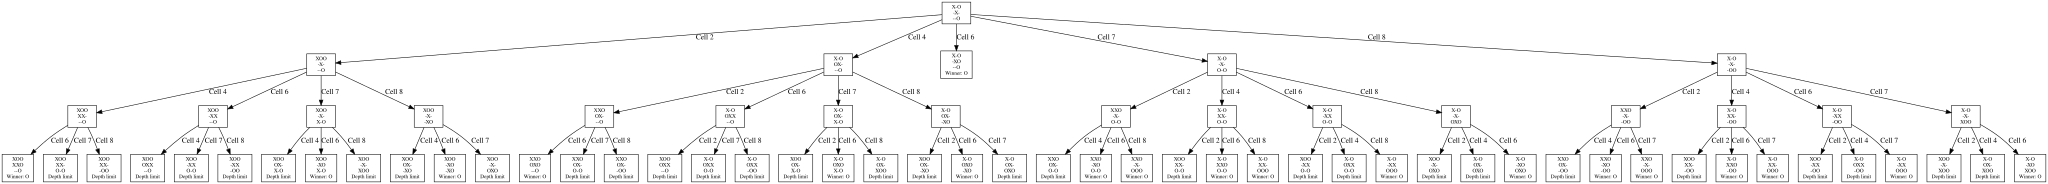

In [ ]:
board = [
    "X", "-", "O",
    "-", "X", "-",
    "-", "-", "O"
]

player = "O"

display(board)

tree, total_nodes = generate_tree(
    board,
    player=player,
    max_depth=3
)

print("Nodes generated:", total_nodes)
tree